# Chapter 3 — OSI vs TCP/IP와 공격 표면 (실습)

## 실습 목표
1. Scapy 로 ICMP·TCP·UDP 패킷을 직접 만들고 캡슐화된 계층을 본다.
2. 만든 패킷을 PCAP 으로 저장하고 ch02 의 tcpdump·tshark 로 다시 읽어 검증한다.
3. 다양한 TCP Flag 조합(SYN/FIN/NULL/Xmas) 패킷을 만들고 스캔 유형과 매핑한다.
4. PCAP 의 각 패킷을 자동으로 계층 분류한다.

## 환경
Colab · 로컬 공통. 패킷 생성은 scapy, 검증은 ch02 에서 익힌 tcpdump·tshark 를 쓴다(없으면 scapy 로 대신 확인한다).



---
## Step 0. 환경 설정

In [ ]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [1]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q scapy

In [2]:
from pathlib import Path
from scapy.all import (
    Ether, IP, TCP, UDP, ICMP, DNS, DNSQR, Raw,
    wrpcap, rdpcap, ls
)
print('Scapy 로드 완료')

Scapy 로드 완료


---
## Step 1. ICMP Echo 패킷 만들기

`ping` 이 보내는 ICMP Echo Request 와 동일한 패킷을 Scapy 로 만든다.
Ethernet / IP / ICMP 세 계층이 자동으로 캡슐화된다.

In [3]:
# ICMP Echo Request 패킷 생성
icmp_pkt = Ether() / IP(src='192.168.1.10', dst='8.8.8.8') / ICMP(type=8, code=0) / Raw(load=b'ping_payload')
icmp_pkt.show()

###[ Ethernet ]###
  dst       = None
  src       = 00:e0:4c:68:00:63
  type      = IPv4
###[ IP ]###
     version   = 4
     ihl       = None
     tos       = 0x0
     len       = None
     id        = 1
     flags     = 
     frag      = 0
     ttl       = 64
     proto     = icmp
     chksum    = None
     src       = 192.168.1.10
     dst       = 8.8.8.8
     \options   \
###[ ICMP ]###
        type      = echo-request
        code      = 0
        chksum    = None
        id        = 0x0
        seq       = 0x0
        unused    = b''
###[ Raw ]###
           load      = b'ping_payload'



관찰: `Ether` → `IP` → `ICMP` → `Raw` 의 캡슐화가 점(`/`)으로 표시된다.
본문 3.4.1절의 IP 헤더 필드(version, ihl, ttl, proto, src, dst)가 모두 자동 채워졌다.

---
## Step 2. TCP·UDP 패킷 만들기

In [4]:
# TCP SYN 패킷 (3-way handshake 의 첫 단계)
tcp_syn = Ether() / IP(src='10.0.0.1', dst='10.0.0.2') / TCP(sport=12345, dport=80, flags='S', seq=1000)
print('--- TCP SYN ---')
tcp_syn.show()

# UDP DNS Query 패킷
udp_dns = Ether() / IP(src='10.0.0.1', dst='8.8.8.8') / UDP(sport=54321, dport=53) / DNS(qd=DNSQR(qname='example.com'))
print('\n--- UDP DNS ---')
udp_dns.show()

--- TCP SYN ---
###[ Ethernet ]###
  dst       = None
  src       = 00:e0:4c:68:00:63
  type      = IPv4
###[ IP ]###
     version   = 4
     ihl       = None
     tos       = 0x0
     len       = None
     id        = 1
     flags     = 
     frag      = 0
     ttl       = 64
     proto     = tcp
     chksum    = None
     src       = 10.0.0.1
     dst       = 10.0.0.2
     \options   \
###[ TCP ]###
        sport     = 12345
        dport     = http
        seq       = 1000
        ack       = 0
        dataofs   = None
        reserved  = 0
        flags     = S
        window    = 8192
        chksum    = None
        urgptr    = 0
        options   = []


--- UDP DNS ---
###[ Ethernet ]###
  dst       = None
  src       = 00:e0:4c:68:00:63
  type      = IPv4
###[ IP ]###
     version   = 4
     ihl       = None
     tos       = 0x0
     len       = None
     id        = 1
     flags     = 
     frag      = 0
     ttl       = 64
     proto     = udp
     chksum    = None
     src  

---
## Step 3. PCAP 저장 + tcpdump·tshark 역검증

만든 패킷을 PCAP 파일로 저장한 후, ch02 에서 익힌 tcpdump·tshark 로 다시 읽어서 헤더가 의도대로 들어갔는지 확인한다.

In [5]:
OUT_PCAP = Path.cwd() / 'synthetic.pcap'

# 3개 패킷을 한 파일에 저장
wrpcap(str(OUT_PCAP), [icmp_pkt, tcp_syn, udp_dns])
print(f'저장됨: {OUT_PCAP.name} ({OUT_PCAP.stat().st_size} bytes)')

저장됨: synthetic.pcap (251 bytes)


In [6]:
import os
import shutil
import subprocess

os.environ["TZ"] = "UTC"
pcap = str(Path.cwd() / "synthetic.pcap")

if shutil.which("tcpdump") and shutil.which("tshark"):
    # tcpdump -v: IP 헤더의 ttl·proto 확인
    print(subprocess.run(["tcpdump", "-r", pcap, "-n", "-v"], capture_output=True, text=True).stdout)
    # tshark 필드 추출: 프레임 번호·IP 프로토콜 번호·주소·TCP 플래그
    print(subprocess.run(["tshark", "-r", pcap, "-T", "fields", "-E", "header=y",
                          "-e", "frame.number", "-e", "ip.proto", "-e", "ip.src", "-e", "ip.dst",
                          "-e", "tcp.flags.str"], capture_output=True, text=True).stdout)
else:
    # tcpdump·tshark 가 없는 환경에서는 scapy 로 같은 필드를 확인한다
    print("frame | ip.proto | src -> dst | tcp.flags")
    for n, p in enumerate(rdpcap(pcap), 1):
        proto = p[IP].proto if p.haslayer(IP) else "-"
        flags = p[TCP].flags if p.haslayer(TCP) else "-"
        print(f"{n} | {proto} | {p[IP].src} -> {p[IP].dst} | {flags}")

00:15:42.469009 IP (tos 0x0, ttl 64, id 1, offset 0, flags [none], proto ICMP (1), length 40)
    192.168.1.10 > 8.8.8.8: ICMP echo request, id 0, seq 0, length 20
00:15:42.478921 IP (tos 0x0, ttl 64, id 1, offset 0, flags [none], proto TCP (6), length 40)
    10.0.0.1.12345 > 10.0.0.2.80: Flags [S], cksum 0x476f (correct), seq 1000, win 8192, length 0
00:15:42.480546 IP (tos 0x0, ttl 64, id 1, offset 0, flags [none], proto UDP (17), length 57)
    10.0.0.1.54321 > 8.8.8.8.53: 0+ A? example.com. (29)



frame.number	ip.proto	ip.src	ip.dst	tcp.flags.str
1	1	192.168.1.10	8.8.8.8	
2	6	10.0.0.1	10.0.0.2	··········S·
3	17	10.0.0.1	8.8.8.8	



관찰: `ip.proto` 가 1(ICMP), 6(TCP), 17(UDP) 로 출력된다.
본문 3.4.1절의 "Protocol" 필드 매핑 표와 일치한다.

---
## Step 4. TCP Flag 조합 — 스캔 유형과 매핑

nmap 이 사용하는 대표 스캔 모드의 패킷을 만들어 본다.

| 스캔 유형 | Flags | nmap 옵션 | 목적 |
|---|---|---|---|
| SYN Scan | `S` | `-sS` | 반응 빠름, 가장 흔함 |
| FIN Scan | `F` | `-sF` | stateless FW 우회 시도 |
| NULL Scan | (없음) | `-sN` | 같은 목적 |
| Xmas Scan | `FPU` | `-sX` | 모든 플래그 on |

In [7]:
# 4가지 스캔 패킷 생성
scans = {
    'SYN':  Ether() / IP(dst='10.0.0.2') / TCP(dport=80, flags='S'),
    'FIN':  Ether() / IP(dst='10.0.0.2') / TCP(dport=80, flags='F'),
    'NULL': Ether() / IP(dst='10.0.0.2') / TCP(dport=80, flags=''),
    'Xmas': Ether() / IP(dst='10.0.0.2') / TCP(dport=80, flags='FPU'),
}
for name, pkt in scans.items():
    flags_str = str(pkt[TCP].flags) or '(none)'
    print(f'{name:5s} scan -> TCP flags = {flags_str}')

SYN   scan -> TCP flags = S
FIN   scan -> TCP flags = F
NULL  scan -> TCP flags = (none)
Xmas  scan -> TCP flags = FPU


> **공격자 시점**: 정상 패킷에 NULL 이나 Xmas Flag 조합은 거의 없다.
> 이런 패킷이 짧은 시간에 다수 포트로 들어오면 stealth 스캔으로 단정해도 좋다.
> ch04 에서 이 패턴을 통계 feature 로 만든다.

---
## Step 5. PCAP 자동 계층 분류기

임의의 PCAP 를 받아 각 패킷이 어느 계층까지 가지는지 자동 분류하는 함수를 만든다.

In [8]:
import pandas as pd

# 각 패킷의 최상위 계층을 식별하는 함수
def top_layer(pkt) -> str:
    """패킷의 가장 위 계층을 OSI 기준으로 반환."""
    if pkt.haslayer('DNS'):
        return 'L7-DNS'
    if pkt.haslayer('HTTPRequest') or pkt.haslayer('HTTPResponse'):
        return 'L7-HTTP'
    if pkt.haslayer(TCP):
        return 'L4-TCP'
    if pkt.haslayer(UDP):
        return 'L4-UDP'
    if pkt.haslayer(ICMP):
        return 'L3-ICMP'
    if pkt.haslayer(IP):
        return 'L3-IP'
    if pkt.haslayer(Ether):
        return 'L2-Ether'
    return 'L1-Unknown'

from scapy.layers.http import HTTPRequest, HTTPResponse  # noqa: F401
packets = rdpcap(str(Path.cwd() / 'synthetic.pcap'))
df = pd.DataFrame({
    'index': range(len(packets)),
    'top_layer': [top_layer(p) for p in packets],
    'summary': [p.summary() for p in packets],
})
df

,index,top_layer,summary
0,0,L3-ICMP,Ether / IP / ICMP 192.168.1.10 > 8.8.8.8 echo-...
1,1,L4-TCP,Ether / IP / TCP 10.0.0.1:12345 > 10.0.0.2:http S
2,2,L7-DNS,Ether / IP / UDP / DNS Qry b'example.com.'


---
## 챌린지

앞서 만든 `synthetic.pcap` 의 각 패킷에 같은 함수를 적용해 보자.
각 계층의 비율을 막대그래프로 그리고, 본문의 "L7 ↔ L4 ↔ L3 분포" 가 일치하는지 확인한다.

In [9]:
# === 한글 폰트 설정 (matplotlib) ===
from pathlib import Path
import matplotlib
from matplotlib import font_manager
for fp in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
           '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf']:
    if Path(fp).exists():
        font_manager.fontManager.addfont(fp)
        matplotlib.rcParams['font.family'] = font_manager.FontProperties(fname=fp).get_name()
        break
matplotlib.rcParams['axes.unicode_minus'] = False

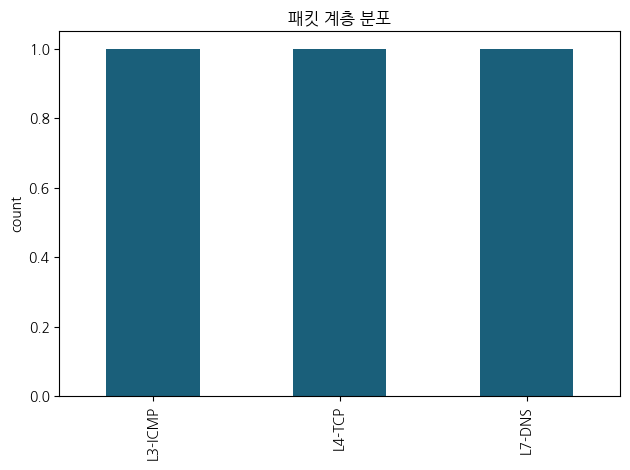

In [10]:
# 챌린지: 패킷의 최상위 계층 분포를 막대그래프로 시각화
import matplotlib.pyplot as plt
packets = rdpcap(str(Path.cwd() / 'synthetic.pcap'))
layer_counts = pd.Series([top_layer(p) for p in packets]).value_counts()
layer_counts.plot(kind='bar', color='#1a5f7a')
plt.title('패킷 계층 분포'); plt.ylabel('count')
plt.tight_layout(); plt.show()

---
## 정리

- Scapy 의 `Ether() / IP() / TCP()` 문법으로 패킷을 계층 단위로 조립할 수 있다.
- TCP Flag 조합만으로 스캔 유형을 식별할 수 있다 — 정상 트래픽에는 거의 없는 조합이 단서.
- PCAP 의 각 패킷을 OSI 계층으로 자동 분류하는 함수는 이후 챕터의 ML feature 추출의 기초가 된다.

다음 챕터(ch04) 에서는 이 패킷 만들기 능력을 활용해 DDoS·Spoofing·Scanning 의 실제 트래픽을 분석한다.